# World Cup 2026 - Task 2.1: regression
Linear regression on the processed dataset (104 matches, 8 pre-match variables).
Input: `wc2026_2_1_dataset.csv`, produced by the dataset processing notebook.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# the processed dataset
DATA_FILE = "wc2026_2_1_dataset.csv"

## 2. Load and check

In [2]:
df = pd.read_csv(DATA_FILE)

# the 8 explanatory variables and the target
X_COLS = ["fifa_points_diff", "host_team1", "host_team2", "same_confederation",
          "round_number", "h2h_matches_played", "h2h_avg_goal_diff", "recent_form_diff"]
Y_COL = "goal_difference"   # team1 goals minus team2 goals

assert len(df) == 104                                   # 104 matches
assert len(X_COLS) == 8                                 # 8 explanatory variables
assert df[X_COLS + [Y_COL]].isna().sum().sum() == 0     # nothing missing
print("All checks passed")
df[X_COLS + [Y_COL]].describe().round(2)

All checks passed


,fifa_points_diff,host_team1,host_team2,same_confederation,round_number,h2h_matches_played,h2h_avg_goal_diff,recent_form_diff,goal_difference
count,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00
mean,55.19,0.11,0.04,0.12,1.60,4.91,-0.04,0.15,0.48
std,231.49,0.31,0.19,0.32,1.12,8.10,1.35,1.31,2.02
min,-489.53,0.00,0.00,0.00,1.00,0.00,-5.00,-4.20,-4.00
25%,-127.75,0.00,0.00,0.00,1.00,0.00,-0.68,-0.62,-1.00
50%,67.76,0.00,0.00,0.00,1.00,2.00,0.00,0.10,0.00
75%,232.26,0.00,0.00,0.00,2.00,5.00,0.50,1.10,2.00
max,506.16,1.00,1.00,1.00,6.00,42.00,5.33,2.50,6.00


## 3. Linear regression
Variables with a p-value under 0.05 are the ones that clearly help the prediction.

In [3]:
X = df[X_COLS]
y = df[Y_COL]
model = sm.OLS(y, sm.add_constant(X)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        goal_difference   R-squared:                       0.478
Model:                            OLS   Adj. R-squared:                  0.434
Method:                 Least Squares   F-statistic:                     10.89
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           8.89e-11
Time:                        14:12:14   Log-Likelihood:                -186.55
No. Observations:                 104   AIC:                             391.1
Df Residuals:                      95   BIC:                             414.9
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.5403      0

## 4. Cross-validation
Trains on 80% of the matches and predicts the other 20%, five times, to see how it does on unseen matches.

In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
pred = cross_val_predict(LinearRegression(), X, y, cv=kf)

print(f"CV R2  : {r2_score(y, pred):.3f}")
print(f"CV MAE : {mean_absolute_error(y, pred):.3f} goals")
print(f"CV RMSE: {np.sqrt(mean_squared_error(y, pred)):.3f} goals")

CV R2  : 0.385
CV MAE : 1.254 goals
CV RMSE: 1.580 goals


## 5. Visualizations

In [5]:
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110,
})
BLUE, ORANGE, GRAY = "#2f6db5", "#d9622b", "#6b7280"

### Chart 1: FIFA points gap vs goal difference

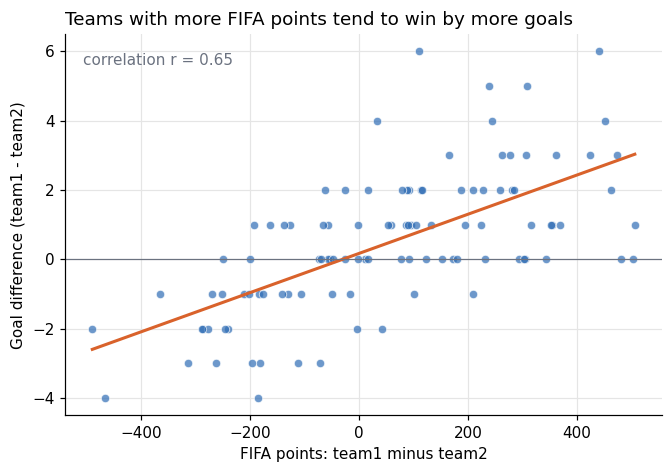

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))

# one dot per match
ax.scatter(df["fifa_points_diff"], df[Y_COL], s=30, color=BLUE, alpha=0.7,
           edgecolor="white", linewidth=0.6)

# straight line that best fits the dots
slope, intercept = np.polyfit(df["fifa_points_diff"], df[Y_COL], 1)
xs = np.linspace(df["fifa_points_diff"].min(), df["fifa_points_diff"].max(), 100)
ax.plot(xs, slope * xs + intercept, color=ORANGE, linewidth=2)

# 0 = draw
ax.axhline(0, color=GRAY, linewidth=0.8)

r = np.corrcoef(df["fifa_points_diff"], df[Y_COL])[0, 1]
ax.text(0.03, 0.95, f"correlation r = {r:.2f}", transform=ax.transAxes, va="top", color=GRAY)
ax.set_title("Teams with more FIFA points tend to win by more goals", loc="left")
ax.set_xlabel("FIFA points: team1 minus team2")
ax.set_ylabel("Goal difference (team1 - team2)")
plt.show()

### Chart 2: actual vs predicted goal difference

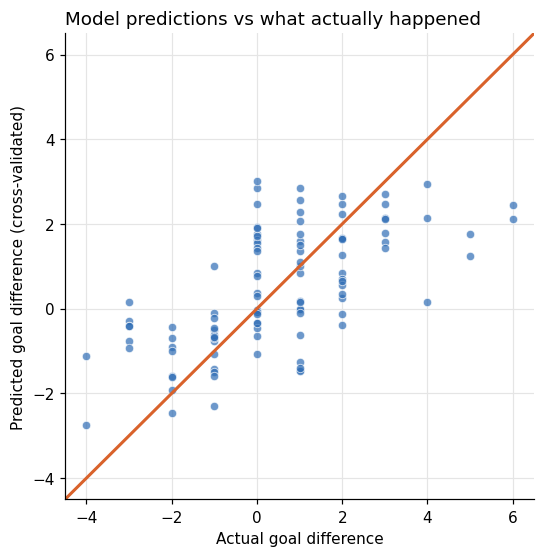

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))

# each match's prediction comes from the cross-validation step
ax.scatter(y, pred, s=30, color=BLUE, alpha=0.7, edgecolor="white", linewidth=0.6)

# on this line, prediction = actual
lim = [min(y.min(), pred.min()) - 0.5, max(y.max(), pred.max()) + 0.5]
ax.plot(lim, lim, color=ORANGE, linewidth=2)
ax.set_xlim(lim); ax.set_ylim(lim)

ax.set_title("Model predictions vs what actually happened", loc="left")
ax.set_xlabel("Actual goal difference")
ax.set_ylabel("Predicted goal difference (cross-validated)")
plt.show()

### Chart 3: how much each variable matters

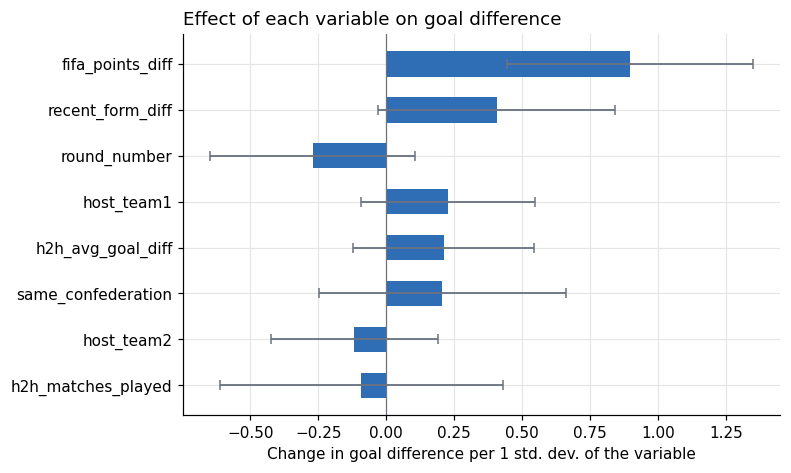

In [8]:
# variables rescaled to the same units so the bars can be compared
Xz = (X - X.mean()) / X.std()
mz = sm.OLS(y, sm.add_constant(Xz)).fit()
coef = mz.params.drop("const")
ci = mz.conf_int().drop("const")
order = coef.abs().sort_values().index   # smallest effect at the bottom

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(order, coef[order], color=BLUE, height=0.55)

# line on each bar = 95% confidence interval
ax.errorbar(coef[order], range(len(order)),
            xerr=[coef[order] - ci.loc[order, 0], ci.loc[order, 1] - coef[order]],
            fmt="none", ecolor=GRAY, capsize=3, linewidth=1.2)

ax.axvline(0, color=GRAY, linewidth=0.8)
ax.set_title("Effect of each variable on goal difference", loc="left")
ax.set_xlabel("Change in goal difference per 1 std. dev. of the variable")
plt.show()